# Regressão - Previsão de Vendas em Supermercados (BigMart)

## 1. Definição do problema

Redes de supermercado precisam saber quanto cada produto vai vender em cada loja para decidir o estoque, evitar falta ou sobra de mercadoria e planejar promoções. Uma estimativa errada gera prejuízo, seja por produto parado e vencendo, seja por perder vendas quando o produto acaba.

**Pergunta principal:** É possível prever o valor de venda de um produto em uma loja a partir das características do produto e da loja?

**Tipo de problema:** Regressão, pois a variável alvo é um valor numérico (valor total vendido).

## 2. Apresentação da base de dados

- **Nome:** BigMart Sales Data (arquivo `Train.csv` do Kaggle, salvo como `bigmart_sales.csv`)
- **Origem:** dados de vendas de 2013 da rede de supermercados BigMart, com 1.559 produtos em 10 lojas de cidades diferentes. Disponível no Kaggle: https://www.kaggle.com/datasets/brijbhushannanda1979/bigmart-sales-data
- **Registros:** 8.523 combinações de produto e loja
- **Colunas:** 12 (11 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| Item_Identifier | id_produto | código do produto |
| Item_Weight | peso | peso do produto |
| Item_Fat_Content | gordura | se o produto tem baixo teor de gordura (Low Fat) ou normal (Regular) |
| Item_Visibility | visibilidade | porcentagem da área de exposição da loja ocupada pelo produto |
| Item_Type | tipo_produto | categoria do produto (laticínios, carnes, bebidas etc.) |
| Item_MRP | preco | preço máximo de venda do produto |
| Outlet_Identifier | id_loja | código da loja |
| Outlet_Establishment_Year | ano_abertura | ano em que a loja foi aberta |
| Outlet_Size | tamanho_loja | tamanho da loja (Small, Medium, High) |
| Outlet_Location_Type | tipo_cidade | tipo de cidade onde fica a loja (Tier 1, 2 ou 3) |
| Outlet_Type | tipo_loja | mercearia ou tipo de supermercado (Type1, Type2, Type3) |
| Item_Outlet_Sales | vendas | **variável alvo**: valor total vendido do produto na loja |

O arquivo `Test.csv` que vem junto no Kaggle não foi usado porque não tem a coluna de vendas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados
df = pd.read_csv('../dados/bigmart_sales.csv')

# renomeando as colunas para facilitar a leitura
df = df.rename(columns={
    'Item_Identifier': 'id_produto',
    'Item_Weight': 'peso',
    'Item_Fat_Content': 'gordura',
    'Item_Visibility': 'visibilidade',
    'Item_Type': 'tipo_produto',
    'Item_MRP': 'preco',
    'Outlet_Identifier': 'id_loja',
    'Outlet_Establishment_Year': 'ano_abertura',
    'Outlet_Size': 'tamanho_loja',
    'Outlet_Location_Type': 'tipo_cidade',
    'Outlet_Type': 'tipo_loja',
    'Item_Outlet_Sales': 'vendas'
})

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 8523
Colunas: 12


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,id_produto,peso,gordura,visibilidade,tipo_produto,preco,id_loja,ano_abertura,tamanho_loja,tipo_cidade,tipo_loja,vendas
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
# tipos de dados
df.dtypes

id_produto          str
peso            float64
gordura             str
visibilidade    float64
tipo_produto        str
preco           float64
id_loja             str
ano_abertura      int64
tamanho_loja        str
tipo_cidade         str
tipo_loja           str
vendas          float64
dtype: object

In [5]:
# valores ausentes
df.isnull().sum()

id_produto         0
peso            1463
gordura            0
visibilidade       0
tipo_produto       0
preco              0
id_loja            0
ano_abertura       0
tamanho_loja    2410
tipo_cidade        0
tipo_loja          0
vendas             0
dtype: int64

In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())

Duplicados: 0


In [7]:
# estatisticas basicas
df.describe().round(2)

,peso,visibilidade,preco,ano_abertura,vendas
count,7060.00,8523.00,8523.00,8523.00,8523.00
mean,12.86,0.07,140.99,1997.83,2181.29
std,4.64,0.05,62.28,8.37,1706.50
min,4.56,0.00,31.29,1985.00,33.29
25%,8.77,0.03,93.83,1987.00,834.25
50%,12.60,0.05,143.01,1999.00,1794.33
75%,16.85,0.09,185.64,2004.00,3101.30
max,21.35,0.33,266.89,2009.00,13086.96


In [8]:
# valores da coluna gordura
df['gordura'].value_counts()

gordura
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

A coluna `gordura` tem a mesma informação escrita de jeitos diferentes: "Low Fat", "LF" e "low fat" significam a mesma coisa, assim como "Regular" e "reg". Isso precisa ser padronizado na preparação.

In [9]:
# produtos com visibilidade zero
print('Produtos com visibilidade 0:', (df['visibilidade'] == 0).sum())

Produtos com visibilidade 0: 526


In [10]:
# em quais lojas estao os valores ausentes
print('Peso ausente por loja:')
print(df[df['peso'].isnull()]['id_loja'].value_counts())
print()
print('Tamanho da loja ausente por loja:')
print(df[df['tamanho_loja'].isnull()]['id_loja'].value_counts())

Peso ausente por loja:
id_loja
OUT027    935
OUT019    528
Name: count, dtype: int64

Tamanho da loja ausente por loja:
id_loja
OUT045    929
OUT017    926
OUT010    555
Name: count, dtype: int64


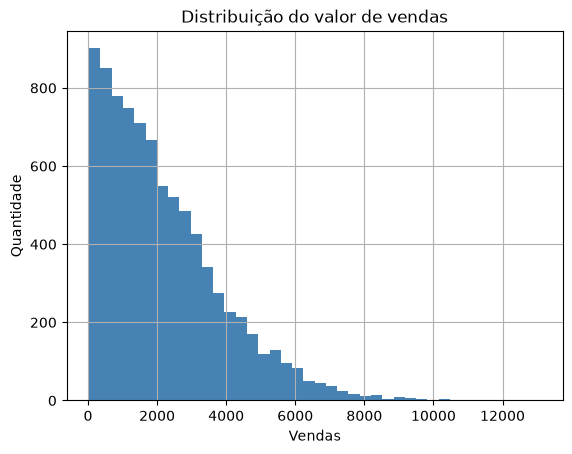

In [11]:
# distribuicao das vendas
df['vendas'].hist(bins=40, color='steelblue')
plt.title('Distribuição do valor de vendas')
plt.xlabel('Vendas')
plt.ylabel('Quantidade')
plt.show()

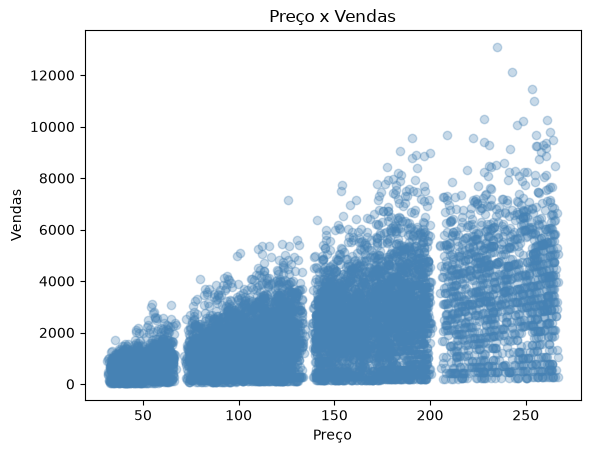

In [12]:
# relacao entre preco e vendas
plt.scatter(df['preco'], df['vendas'], alpha=0.3, color='steelblue')
plt.title('Preço x Vendas')
plt.xlabel('Preço')
plt.ylabel('Vendas')
plt.show()

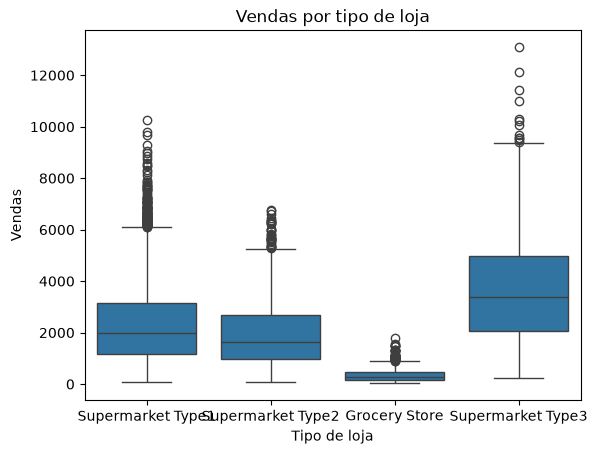

In [13]:
# vendas por tipo de loja
sns.boxplot(data=df, x='tipo_loja', y='vendas')
plt.title('Vendas por tipo de loja')
plt.xlabel('Tipo de loja')
plt.ylabel('Vendas')
plt.show()

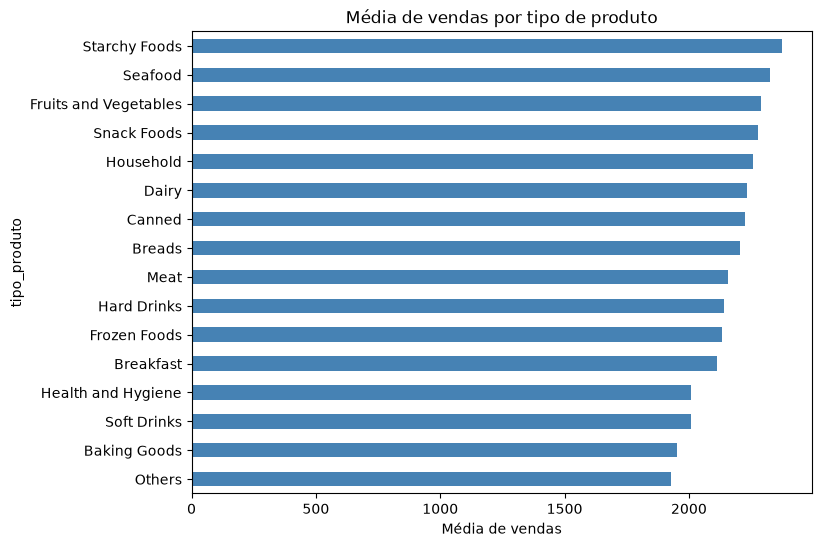

In [14]:
# media de vendas por tipo de produto
df.groupby('tipo_produto')['vendas'].mean().sort_values().plot(kind='barh', color='steelblue', figsize=(8, 6))
plt.title('Média de vendas por tipo de produto')
plt.xlabel('Média de vendas')
plt.show()

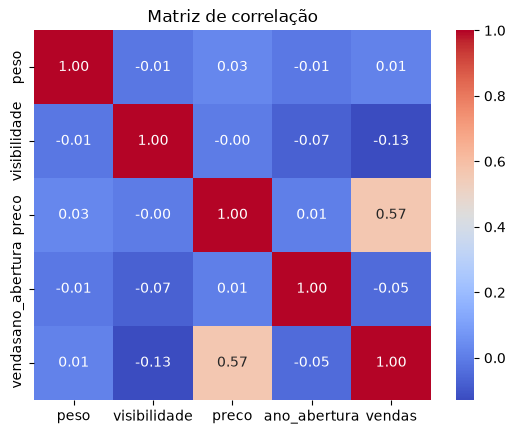

In [15]:
# matriz de correlacao das colunas numericas
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 8.523 registros e nenhum duplicado.
- Existem valores ausentes em duas colunas: **peso** (1.463) e **tamanho da loja** (2.410). O peso está faltando só em duas lojas (OUT027 e OUT019), e o tamanho está faltando em três lojas inteiras (OUT010, OUT017 e OUT045).
- A coluna **gordura** tem 5 escritas diferentes para apenas 2 categorias.
- 526 produtos têm **visibilidade 0**, o que não faz sentido para um produto que foi vendido. Provavelmente é erro de registro.
- As vendas vão de 33 a 13.087, com média de 2.181. O histograma mostra que a maioria dos produtos vende pouco e poucos vendem muito (distribuição assimétrica para a direita).
- O **preço** é a variável numérica mais relacionada às vendas (correlação de 0,57): produtos mais caros geram um valor de venda maior.
- O **tipo de loja** faz muita diferença: as mercearias (Grocery Store) vendem em média 340, enquanto o Supermarket Type3 vende em média 3.694.
- O **tipo de produto** quase não muda a média de vendas (todas as categorias ficam entre 1.926 e 2.374).

## 4. Preparação dos dados

Decisões tomadas:

1. **Duplicados:** a base não tem registros duplicados.
2. **Peso ausente:** o peso é uma característica do produto e não da loja, e o mesmo produto aparece em várias lojas. Então o peso ausente foi preenchido com o peso do mesmo produto registrado nas outras lojas. Se ainda sobrar algum valor ausente, ele é preenchido com a mediana.
3. **Tamanho da loja ausente:** o tamanho está faltando para três lojas inteiras, e não dá para descobrir o valor certo pelos dados. Por isso foi criada a categoria "Desconhecido" em vez de inventar um tamanho.
4. **Gordura:** as escritas "LF" e "low fat" foram trocadas por "Low Fat", e "reg" por "Regular".
5. **Visibilidade zero:** foi tratada como valor ausente e preenchida com a mediana da visibilidade do mesmo produto nas outras lojas.
6. **Ano de abertura:** foi transformado em **anos de funcionamento** (2013 menos o ano de abertura), porque os dados são de 2013 e fica mais fácil de interpretar.
7. **Códigos removidos:** `id_produto` e `id_loja` são só códigos de identificação. As características da loja já estão nas outras colunas.
8. **Variáveis categóricas:** gordura, tipo de produto, tamanho da loja, tipo de cidade e tipo de loja foram transformadas com **one-hot encoding**.
9. **Treino e teste:** 80% treino e 20% teste.
10. **Padronização:** `StandardScaler`, porque o preço vai até 266 enquanto a visibilidade fica entre 0 e 0,33.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# preenchendo o peso com o peso do mesmo produto em outras lojas
peso_produto = df.groupby('id_produto')['peso'].transform('mean')
df['peso'] = df['peso'].fillna(peso_produto)
print('Peso ausente depois de usar o mesmo produto:', df['peso'].isnull().sum())
df['peso'] = df['peso'].fillna(df['peso'].median())

# tamanho da loja ausente vira uma categoria
df['tamanho_loja'] = df['tamanho_loja'].fillna('Desconhecido')

# padronizando a coluna gordura
df['gordura'] = df['gordura'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
print(df['gordura'].value_counts())

Peso ausente depois de usar o mesmo produto: 4
gordura
Low Fat    5517
Regular    3006
Name: count, dtype: int64


In [17]:
# visibilidade zero vira a mediana da visibilidade do mesmo produto
df['visibilidade'] = df['visibilidade'].replace(0, np.nan)
visibilidade_produto = df.groupby('id_produto')['visibilidade'].transform('median')
df['visibilidade'] = df['visibilidade'].fillna(visibilidade_produto)
df['visibilidade'] = df['visibilidade'].fillna(df['visibilidade'].median())

# anos de funcionamento da loja
df['anos_funcionamento'] = 2013 - df['ano_abertura']

# removendo colunas que nao serao usadas
df = df.drop(columns=['id_produto', 'id_loja', 'ano_abertura'])

print('Valores ausentes:', df.isnull().sum().sum())
print('Visibilidade zero:', (df['visibilidade'] == 0).sum())

Valores ausentes: 0
Visibilidade zero: 0


In [18]:
# one-hot encoding
df = pd.get_dummies(df, columns=['gordura', 'tipo_produto', 'tamanho_loja', 'tipo_cidade', 'tipo_loja'], dtype=int)

print('Colunas depois do one-hot:', df.shape[1])
df.head()

Colunas depois do one-hot: 34


,peso,visibilidade,preco,vendas,anos_funcionamento,gordura_Low Fat,gordura_Regular,tipo_produto_Baking Goods,tipo_produto_Breads,tipo_produto_Breakfast,...,tamanho_loja_High,tamanho_loja_Medium,tamanho_loja_Small,tipo_cidade_Tier 1,tipo_cidade_Tier 2,tipo_cidade_Tier 3,tipo_loja_Grocery Store,tipo_loja_Supermarket Type1,tipo_loja_Supermarket Type2,tipo_loja_Supermarket Type3
0,9.30,0.016047,249.8092,3735.1380,14,1,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0
1,5.92,0.019278,48.2692,443.4228,4,0,1,0,0,0,...,0,1,0,0,0,1,0,0,1,0
2,17.50,0.016760,141.6180,2097.2700,14,1,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0
3,19.20,0.022934,182.0950,732.3800,15,0,1,0,0,0,...,0,0,0,0,0,1,1,0,0,0
4,8.93,0.013254,53.8614,994.7052,26,1,0,0,0,0,...,1,0,0,0,0,1,0,1,0,0


In [19]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='vendas')
y = df['vendas']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)

Treino: (6818, 33)
Teste: (1705, 33)


## 5. Escolha dos modelos

Foram usados os mesmos 5 modelos de regressão do notebook de notas, para manter a comparação:

- **Regressão Linear:** modelo base. Faz sentido testar porque o preço tem uma relação quase linear com as vendas.
- **Ridge:** regressão linear com penalização, que ajuda quando existem muitas colunas criadas pelo one-hot.
- **Árvore de Decisão Regressora:** consegue capturar regras como "se for mercearia, vende pouco", que uma reta não captura bem. Limitada a profundidade 5 para não decorar os dados.
- **Random Forest Regressor:** média de várias árvores. Foi limitada a profundidade 10 e no mínimo 20 registros por folha, porque as vendas variam muito e árvores sem limite acabariam decorando o ruído.
- **KNN Regressor:** prevê a venda como a média dos 15 produtos mais parecidos no treino.

## 6. Treinamento dos modelos

- **Dados de treino:** 6.818 registros (80%)
- **Dados de teste:** 1.705 registros (20%)

Cada modelo aprende com os dados de treino (`fit`) e depois prevê o valor de venda dos registros de teste (`predict`).

In [20]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

modelos = {
    'Regressão Linear': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(max_depth=10, min_samples_leaf=20, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=15)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Linear - treinado
Ridge - treinado


Árvore de Decisão - treinado


Random Forest - treinado
KNN - treinado


## 7. Avaliação dos modelos

Métricas utilizadas:

- **MAE (erro absoluto médio):** em média, quanto a previsão erra o valor de venda, para mais ou para menos.
- **MSE (erro quadrático médio):** média dos erros ao quadrado. Pune mais os erros grandes.
- **RMSE (raiz do MSE):** o MSE na mesma unidade das vendas, mais fácil de interpretar.
- **R²:** quanto da variação das vendas o modelo consegue explicar (quanto mais perto de 1, melhor).

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []
for nome, y_prev in previsoes.items():
    mse = mean_squared_error(y_teste, y_prev)
    resultados.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(y_teste, y_prev),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(y_teste, y_prev)
    })

tabela = pd.DataFrame(resultados).sort_values('R²', ascending=False)
tabela.round(3)

,Modelo,MAE,MSE,RMSE,R²
3,Random Forest,716.302,1052442.630,1025.886,0.613
2,Árvore de Decisão,724.004,1063771.864,1031.393,0.609
0,Regressão Linear,791.276,1142640.798,1068.944,0.580
1,Ridge,791.293,1142706.101,1068.974,0.580
4,KNN,877.320,1427485.151,1194.774,0.475


In [22]:
# comparando o R2 no treino e no teste para ver se algum modelo decorou os dados
comparacao = []
for nome, modelo in modelos.items():
    comparacao.append({
        'Modelo': nome,
        'R² treino': r2_score(y_treino, modelo.predict(X_treino_pad)),
        'R² teste': r2_score(y_teste, previsoes[nome])
    })

pd.DataFrame(comparacao).round(3)

,Modelo,R² treino,R² teste
0,Regressão Linear,0.559,0.580
1,Ridge,0.559,0.580
2,Árvore de Decisão,0.601,0.609
3,Random Forest,0.647,0.613
4,KNN,0.525,0.475


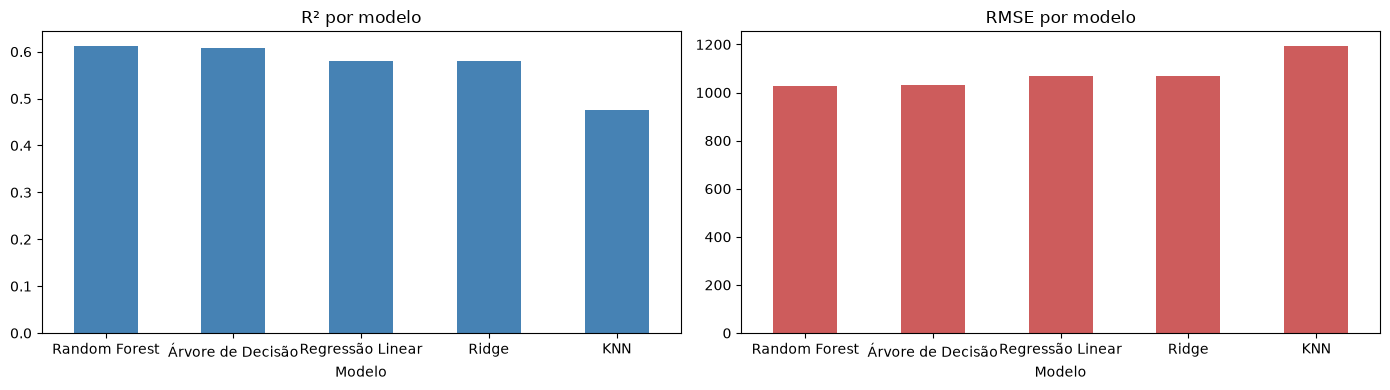

In [23]:
# comparando o R2 e o RMSE dos modelos
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
tabela.plot(x='Modelo', y='R²', kind='bar', ax=eixos[0], legend=False, color='steelblue')
eixos[0].set_title('R² por modelo')
eixos[0].tick_params(axis='x', rotation=0)
tabela.plot(x='Modelo', y='RMSE', kind='bar', ax=eixos[1], legend=False, color='indianred')
eixos[1].set_title('RMSE por modelo')
eixos[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Melhor modelo pelo R²: Random Forest


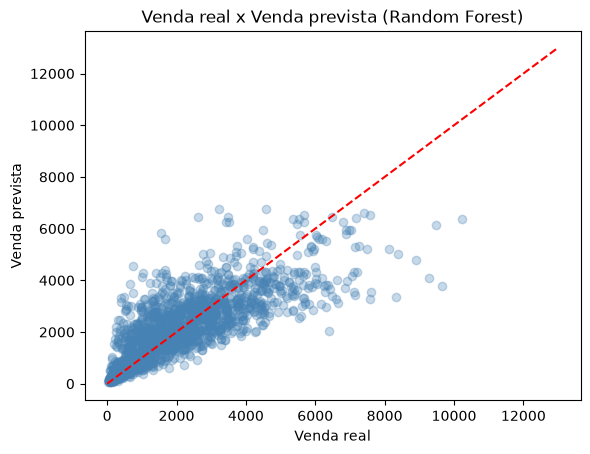

In [24]:
# valores reais x previstos do melhor modelo
melhor_nome = tabela.iloc[0]['Modelo']
print('Melhor modelo pelo R²:', melhor_nome)

plt.scatter(y_teste, previsoes[melhor_nome], alpha=0.3, color='steelblue')
plt.plot([0, 13000], [0, 13000], color='red', linestyle='--')
plt.title('Venda real x Venda prevista (' + melhor_nome + ')')
plt.xlabel('Venda real')
plt.ylabel('Venda prevista')
plt.show()

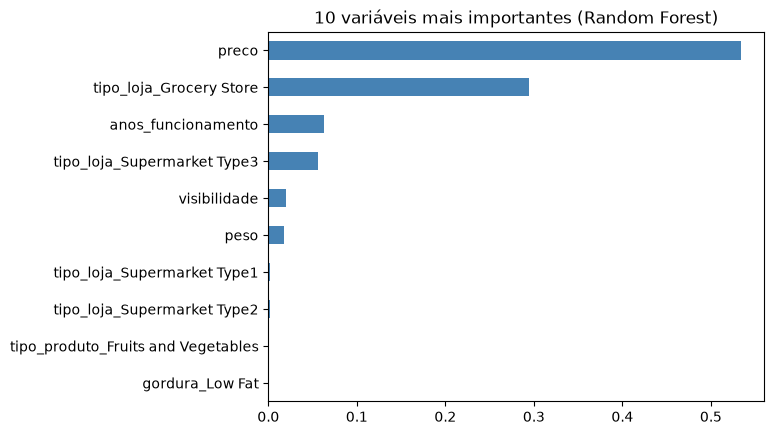

In [25]:
# variaveis mais importantes para o random forest
importancia = pd.Series(modelos['Random Forest'].feature_importances_, index=X.columns)
importancia.sort_values().tail(10).plot(kind='barh', color='steelblue')
plt.title('10 variáveis mais importantes (Random Forest)')
plt.show()

**Interpretação dos resultados:**

- O melhor modelo foi o **Random Forest**, com R² de 0,613. Isso quer dizer que ele explica cerca de 61% da variação das vendas. A Árvore de Decisão ficou muito perto (0,609).
- O **MAE** do Random Forest foi de 716, ou seja, em média a previsão erra 716 para mais ou para menos. Como a venda média no teste é de cerca de 2.100, o erro ainda é grande, perto de um terço do valor médio.
- O **RMSE** (1.026) é bem maior que o MAE (716). Isso indica que existem alguns erros muito grandes, principalmente nos produtos que vendem muito.
- A Regressão Linear e a Ridge tiveram resultados iguais (R² de 0,580). A penalização da Ridge não fez diferença porque há muitos registros para poucas colunas.
- O **KNN** foi o pior (R² de 0,475) e foi o único que ficou com o teste bem abaixo do treino.
- Na tabela de treino x teste, o Random Forest limitado ficou com 0,647 no treino e 0,613 no teste, uma diferença pequena. Isso mostra que limitar a profundidade funcionou e o modelo não decorou os dados.
- No gráfico de valores reais x previstos, os pontos se espalham bastante, e o modelo quase nunca prevê valores acima de 6.000 mesmo quando a venda real foi maior. Ele tende a "puxar" as previsões para perto da média.
- Pela importância do Random Forest, as duas informações principais são o **preço** (53%) e se a loja é uma **mercearia** (30%), o que confirma a análise exploratória. O peso, a gordura e o tipo de produto quase não ajudam.